In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml_security import ChallengeClient
from ml_security.utils import parse_csv, save_predictions_csv

In [2]:
client = ChallengeClient.from_env()

run_dir = Path("notebook_runs/challenge3_extraction")
run_dir.mkdir(parents=True, exist_ok=True)

info_path          = run_dir / "task3_info.json"
test_features_path = run_dir / "test_features.csv"
train_data_path    = run_dir / "train_queries.csv"
predictions_path   = run_dir / "predictions.csv"

print(f"Run directory : {run_dir}")
print(f"Info cache    : {info_path}")
print(f"Test features : {test_features_path}")
print(f"Train queries : {train_data_path}")

Run directory : notebook_runs/challenge3_extraction
Info cache    : notebook_runs/challenge3_extraction/task3_info.json
Test features : notebook_runs/challenge3_extraction/test_features.csv
Train queries : notebook_runs/challenge3_extraction/train_queries.csv


In [3]:
info = client.get_task3_info()
info_path.write_text(json.dumps(info, indent=2))

print("=== Task description ===")
print(info.get("task_description", ""))
print()
print(f"Query budget  : {info['query_budget']}")
print(f"Queries used  : {info['queries_used']}")
print(f"Queries left  : {info['query_budget'] - info['queries_used']}")
print(f"Test set size : {info['test_set_size']}")
print()
print("=== Features ===")
for feat in info["features"]:
    print(f"  {feat['name']:<20} dtype={feat['dtype']:<6} "
          f"range=[{feat.get('min_value', '?')}, {feat.get('max_value', '?')}]  "
          f"{feat.get('description', '')}")
print()
print("=== Sample row ===")
print(json.dumps(info["sample"], indent=2))

=== Task description ===
Чёрная модель кредитного скоринга принимает заявку на кредит и решает: одобрить (1) или отказать (0). Ваша задача — извлечь поведение модели, отправляя запросы через API, и обучить суррогатную модель. Затем скачайте тестовый набор признаков и отправьте предсказания.

Query budget  : 2000
Queries used  : 1
Queries left  : 1999
Test set size : 500

=== Features ===
  age                  dtype=int    range=[18.0, 75.0]  Возраст заёмщика (полных лет)
  income               dtype=float  range=[10.0, 500.0]  Ежемесячный доход (тыс. руб.)
  loan_amount          dtype=float  range=[10.0, 5000.0]  Запрашиваемая сумма кредита (тыс. руб.)
  loan_term            dtype=int    range=[6.0, 360.0]  Срок кредита (месяцев)
  credit_history_length dtype=int    range=[0.0, 360.0]  Длительность кредитной истории (месяцев)
  num_active_loans     dtype=int    range=[0.0, 10.0]  Количество активных кредитов
  num_late_payments    dtype=int    range=[0.0, 20.0]  Количество просрочек з

In [4]:
# Send the exact sample row to confirm the API round-trip and see what the model returns
sample = {k: v for k, v in info["sample"].items() if k != "approved"}
sample_response = client.query_model(sample)

print("Sample query")
print("  input    :", sample)
print("  response :", sample_response)
print(f"  prediction       : {sample_response['prediction']}")
print(f"  probability      : {sample_response['probability']:.4f}")
print(f"  queries remaining: {sample_response['queries_remaining']}")

Sample query
  input    : {'age': 36.0, 'income': 227.0, 'loan_amount': 1806.3, 'loan_term': 38.0, 'credit_history_length': 162.0, 'num_active_loans': 10.0, 'num_late_payments': 6.0, 'debt_to_income': 0.023, 'employment_years': 28.9, 'has_property': 1.0, 'education': 0.0, 'marital_status': 0.0}
  response : {'prediction': 1, 'probability': 0.9938, 'queries_remaining': 1998}
  prediction       : 1
  probability      : 0.9938
  queries remaining: 1998


In [5]:
raw = client.get_test_features()

# Save raw CSV to disk
test_features_path.write_text(raw["csv"])

print(f"Columns  : {raw['columns']}")
print(f"Num rows : {raw['num_rows']}")
print(f"Saved to : {test_features_path}")

Columns  : ['age', 'income', 'loan_amount', 'loan_term', 'credit_history_length', 'num_active_loans', 'num_late_payments', 'debt_to_income', 'employment_years', 'has_property', 'education', 'marital_status']
Num rows : 500
Saved to : notebook_runs/challenge3_extraction/test_features.csv


In [8]:
test_df = pd.read_csv(test_features_path)

print(f"Shape: {test_df.shape}")
print()
print(test_df.dtypes)
print()
print(test_df.describe())

Shape: (500, 12)

age                        int64
income                   float64
loan_amount              float64
loan_term                  int64
credit_history_length      int64
num_active_loans           int64
num_late_payments          int64
debt_to_income           float64
employment_years         float64
has_property               int64
education                  int64
marital_status             int64
dtype: object

             age      income  loan_amount   loan_term  credit_history_length  \
count  500.00000  500.000000   500.000000  500.000000             500.000000   
mean    46.04600  268.727400  2500.474400  184.580000             179.426000   
std     16.54071  140.175123  1459.144486  103.439098              99.390591   
min     18.00000   10.700000    27.200000    7.000000               0.000000   
25%     32.00000  158.700000  1170.775000   95.000000              99.750000   
50%     44.00000  274.100000  2491.550000  181.500000             172.000000   
75%     61.

In [9]:
feature_names = [f["name"] for f in info["features"]]

In [10]:
# Probe a small random slice of the hidden test set through the API.
N = 100
sampled_rows = test_df.sample(n=min(N, len(test_df)), random_state=42)
sampled_predictions = []

print(f"Trying {len(sampled_rows)} randomly selected test rows")
print()

for row_idx, row in sampled_rows.iterrows():
    features = {
        name: (value.item() if hasattr(value, "item") else value)
        for name, value in row[feature_names].items()
    }
    response = client.query_model(features)
    sampled_predictions.append({
        "row_index": int(row_idx),
        **response,
    })

    print(f"Row {row_idx}")
    print("  input       :", features)
    print(f"  prediction  : {response['prediction']}")
    print(f"  probability : {response['probability']:.4f}")
    print(f"  queries remaining: {response['queries_remaining']}")
    print()

pd.DataFrame(sampled_predictions)

Trying 100 randomly selected test rows

Row 361
  input       : {'age': 54.0, 'income': 379.8, 'loan_amount': 3944.4, 'loan_term': 324.0, 'credit_history_length': 120.0, 'num_active_loans': 9.0, 'num_late_payments': 13.0, 'debt_to_income': 0.36, 'employment_years': 7.2, 'has_property': 1.0, 'education': 0.0, 'marital_status': 1.0}
  prediction  : 0
  probability : 0.0012
  queries remaining: 1997

Row 73
  input       : {'age': 38.0, 'income': 459.6, 'loan_amount': 3565.1, 'loan_term': 263.0, 'credit_history_length': 97.0, 'num_active_loans': 4.0, 'num_late_payments': 1.0, 'debt_to_income': 0.086, 'employment_years': 36.1, 'has_property': 0.0, 'education': 2.0, 'marital_status': 0.0}
  prediction  : 1
  probability : 0.9984
  queries remaining: 1996

Row 374
  input       : {'age': 28.0, 'income': 292.4, 'loan_amount': 1171.0, 'loan_term': 17.0, 'credit_history_length': 282.0, 'num_active_loans': 5.0, 'num_late_payments': 14.0, 'debt_to_income': 0.583, 'employment_years': 12.8, 'has_pr

,row_index,prediction,probability,queries_remaining
0,361,0,0.0012,1997
1,73,1,0.9984,1996
2,374,1,0.9859,1995
3,155,0,0.0046,1994
4,104,0,0.3762,1993
...,...,...,...,...
95,347,1,0.9827,1902
96,86,1,0.9952,1901
97,75,0,0.0985,1900
98,438,0,0.3415,1899


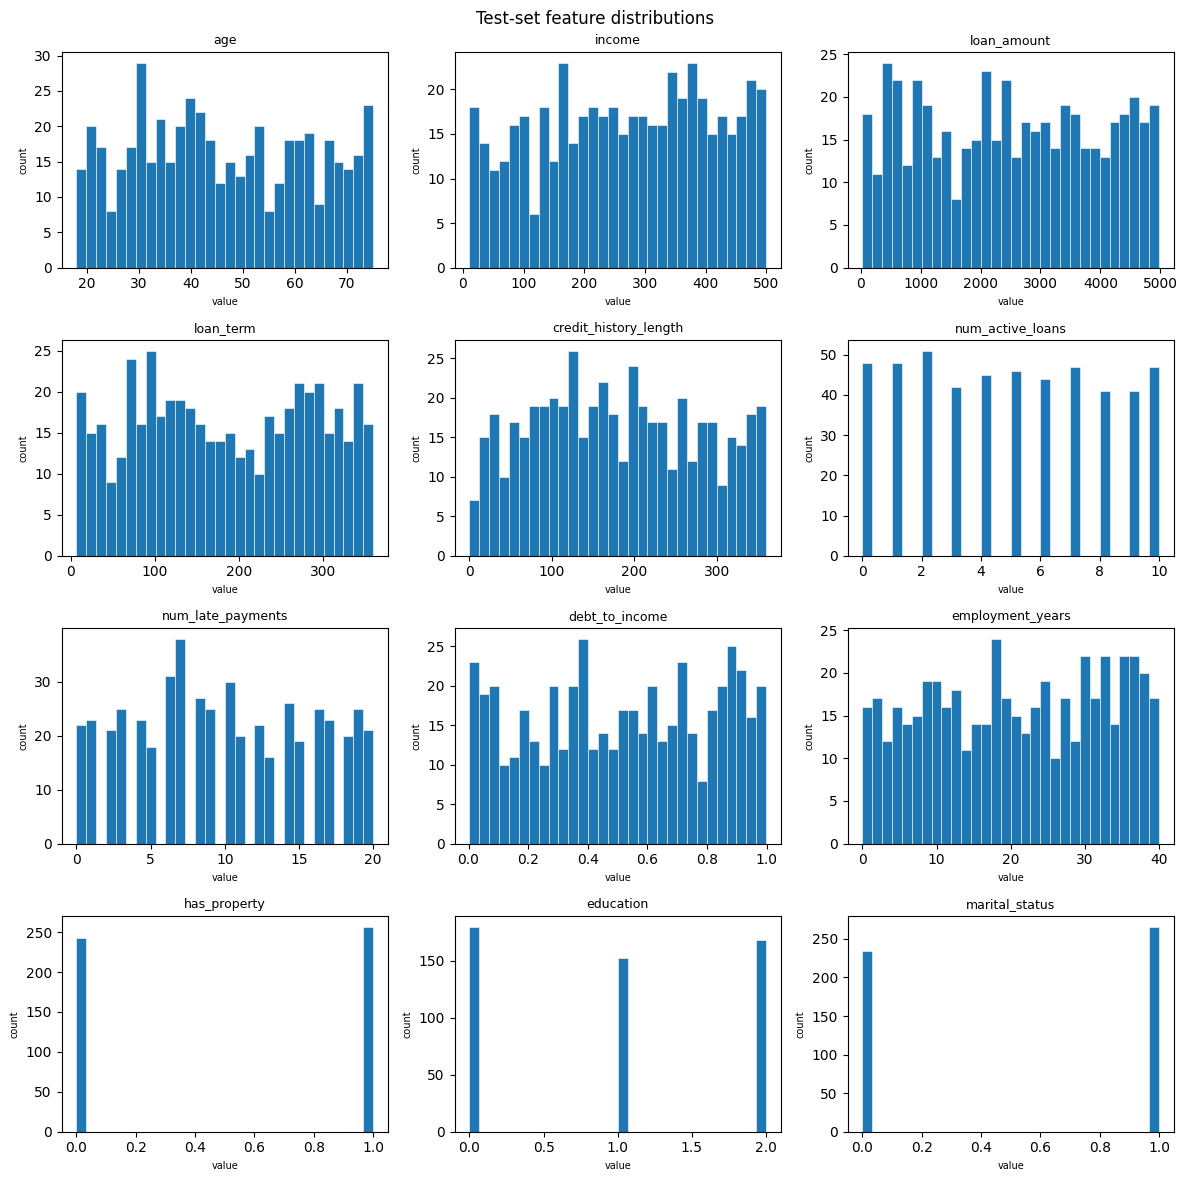

In [8]:
n_feats = len(feature_names)
ncols = 3
nrows = (n_feats + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = np.array(axes).reshape(-1)

for i, feat_name in enumerate(feature_names):
    if feat_name in test_df.columns:
        axes[i].hist(test_df[feat_name].dropna(), bins=30, edgecolor="white", linewidth=0.4)
        axes[i].set_title(feat_name, fontsize=9)
        axes[i].set_xlabel("value", fontsize=7)
        axes[i].set_ylabel("count", fontsize=7)

for j in range(n_feats, len(axes)):
    axes[j].axis("off")

plt.suptitle("Test-set feature distributions", fontsize=12)
plt.tight_layout()
plt.show()